<div class="alert alert-info">
<h1>Count Regression</h1>
<h4>Environmental Statistics 2</h4>
C.F. Dormann
</div>

There are two things to learn today:<br>
   -  using model dispersion to tell between Poisson and negative binomial distribution; <br>
   -  moving back and forth between the response and the link scale (R-issues).

### 1.0  Exercise 1 
It is not always easy to find good environmental data, so here we resort to a political analysis of military coups in sub-Saharan Africa (since independence of many countries in 1989). 

In [18]:
# Call the necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices
import scipy

# call dataset
africa = pd.read_csv("africa.csv")

# Reset the index by replacing with country
africa = africa.set_index('country')
africa.describe()


,miltcoup,oligarchy,pollib,parties,pctvote,popn,size,numelec,numregim
count,47.000000,47.000000,42.000000,47.000000,41.000000,47.000000,47.000000,47.000000,47.000000
mean,1.404255,4.446809,1.666667,15.957447,31.881220,10.953064,516.712766,6.191489,2.510638
std,1.715144,5.751403,0.570266,11.458730,17.465135,18.558382,591.161189,3.876564,1.018787
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.067000,0.500000,0.000000,1.000000
25%,0.000000,0.000000,1.000000,10.000000,18.900000,1.450000,33.000000,4.000000,2.000000
50%,1.000000,1.000000,2.000000,13.000000,28.950000,5.600000,274.000000,6.000000,3.000000
75%,2.000000,9.000000,2.000000,19.000000,43.040000,11.450000,813.000000,8.500000,3.000000
max,6.000000,18.000000,2.000000,62.000000,77.400000,113.800000,2506.000000,14.000000,4.000000


In [2]:
africa.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47 entries, Angola to Zimbabwe
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   miltcoup   47 non-null     int64  
 1   oligarchy  47 non-null     int64  
 2   pollib     42 non-null     float64
 3   parties    47 non-null     int64  
 4   pctvote    41 non-null     float64
 5   popn       47 non-null     float64
 6   size       47 non-null     float64
 7   numelec    47 non-null     int64  
 8   numregim   47 non-null     int64  
dtypes: float64(4), int64(5)
memory usage: 3.7+ KB


In [2]:
# Drop na
africa = africa.dropna()


### 1.1  Plot data
Plot the effect of number of successful military coups (‘miltcoup’) as a function of number of years ruled by military (since 1989).

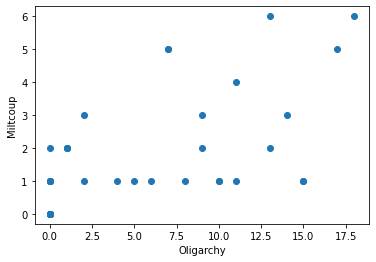

In [18]:
# The plot
plt.scatter(x="oligarchy", y="miltcoup", data=africa)
plt.xlabel("Oligarchy")
plt.ylabel("Miltcoup")
plt.show()

(array([18.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 14.,  0.,  0.,  0.,  0.,
         0.,  6.,  0.,  0.,  3.,  0.,  0.,  1.,  0.,  0.,  3.,  2.]),
 array([0.        , 0.07783641, 0.15567281, 0.23350922, 0.31134562,
        0.38918203, 0.46701844, 0.54485484, 0.62269125, 0.70052765,
        0.77836406, 0.85620047, 0.93403687, 1.01187328, 1.08970968,
        1.16754609, 1.2453825 , 1.3232189 , 1.40105531, 1.47889171,
        1.55672812, 1.63456453, 1.71240093, 1.79023734, 1.86807374,
        1.94591015]),
 <BarContainer object of 25 artists>)

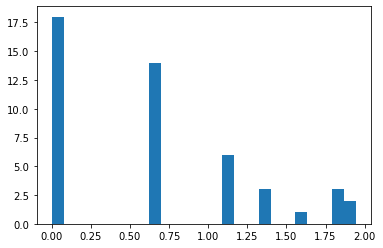

In [14]:
plt.hist(np.log(africa['miltcoup'] + 1), bins=25)

### 1.2  Plot data with transformed data
Both variables are count data, and often they benefit from square-root or logarithmic transformation. The reason is that the Poisson and negative binomial distribution are right-skewed and hence such a transformation makes the variables more akin to the symmetric distribution our eyes are used to. (Of course there is nothing wrong with plotting the data as they are!) <br>
Also count distributions typically use a logarithmic link, and hence such a transformation would simulate what the y-axis looks like at the link scale. (Note that for any base 𝑏: log<sub>b</sub> 0 = −$\infty$, hence it is common to see a value of 1 added to the response variable for plotting only.)


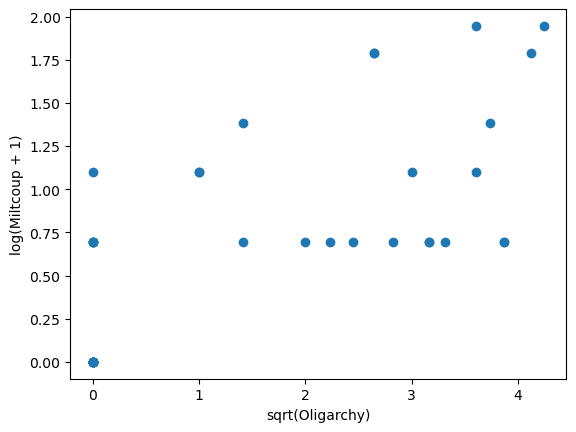

In [5]:
# log root Transformed miltcoup
# square root Transformed oligarchy

# the plot

plt.scatter(x=np.sqrt(africa['oligarchy']), y=np.log(africa['miltcoup'] + 1))
plt.xlabel("sqrt(Oligarchy)")
plt.ylabel("log(Miltcoup + 1)")
plt.show()

### 1.3  Analyse, assuming a Poisson distribution
Analyse effect of square-root transformed years of military oligarchy on military coups, assuming a Poisson distribution (for the response).

In [20]:
#1. using sm.GLM()
expr = """miltcoup ~ np.sqrt(oligarchy)"""

y, X = dmatrices(expr, africa, return_type='dataframe') # matrix form

# Poisson 
fpois = sm.GLM(y, X, family=sm.families.Poisson()).fit()
fpois.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:                            GLM   Df Residuals:                       45
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -61.504
Date:                Tue, 21 Oct 2025   Deviance:                       49.329
Time:                        09:51:34   Pearson chi2:                     48.6
No. Iterations:                     5   Pseudo R-squ. (CS):             0.6132
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.7901      0.269     -2.935      0.003      -1.318      -0.262
np.sqrt(oligarchy)     0.5399      0.088      6.131      0.000       0.367       0.713
======================================================================================
"""

In [11]:
# 2. using sm.GLM.from_formula()

formula = "miltcoup ~ np.sqrt(oligarchy)"

# Poisson 
fpois2 = sm.GLM.from_formula(formula, data=africa, family=sm.families.Poisson()).fit()
fpois2.summary() 



<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   36
Model:                            GLM   Df Residuals:                       34
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -52.030
Date:                Tue, 21 Oct 2025   Deviance:                       39.252
Time:                        09:44:44   Pearson chi2:                     38.2
No. Iterations:                     5   Pseudo R-squ. (CS):             0.5236
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.5462      0.291     -1.878      0.060      -1.116       0.024
np.sqrt(oligarchy)     0.4555      0.095      4.789      0.000       0.269       0.642
======================================================================================
"""

In [12]:
#3. Using smf.glm()
formula = "miltcoup ~ np.sqrt(oligarchy)"

# Poisson 
fpois3 = smf.glm(formula, data=africa, family=sm.families.Poisson()).fit()
fpois3.summary() 

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   36
Model:                            GLM   Df Residuals:                       34
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -52.030
Date:                Tue, 21 Oct 2025   Deviance:                       39.252
Time:                        09:45:37   Pearson chi2:                     38.2
No. Iterations:                     5   Pseudo R-squ. (CS):             0.5236
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.5462      0.291     -1.878      0.060      -1.116       0.024
np.sqrt(oligarchy)     0.4555      0.095      4.789      0.000       0.269       0.642
======================================================================================
"""

### 1.4   What does the dispersion look like?

In [36]:
# dispersion
fpois.deviance/fpois.df_resid


1.0961894810369244

*Answer*: Looks good!

### 1.5  Analyse, assuming a neg bin distribution
Nevertheless, run an analysis assuming a negative binomial distribution.

In [25]:
# First: what alpha value to use?
''' Before fitting the Negative binomial, we need to first estimate the what `alpha` value to use?
'''

# 1. We will now fit the auxiliary OLS regression model on the data set and use the fitted model to get the value of α.

# Add the λ vector as a new column called ‘my_lambda’ to the DataFrame.
africa2 = africa.copy()
africa2['lambda_'] = fpois.mu


# 2. Next, add the expression [(Yi-λi)^2-λi]/λi =  α*λi + 0
# This new column will store the values of the dependent variable of the OLS regression.

africa2['ols_dep'] = africa2.apply(lambda x: ((x['miltcoup'] - x['lambda_'])**2 - x['lambda_']) / x['lambda_'], axis=1)

ols_expr = """ols_dep ~ lambda_ - 1"""  # do not to use an intercept of regression
    
olsr_results = smf.ols(ols_expr, africa2).fit()
print('Alpha is : ' ,olsr_results.params)
print('tvalue is : ', olsr_results.tvalues)

'''
Here our α=0.047552. Recall that the variance formular is Var= mu + α*mu, so if α=0, then variance will be = mean.
If the value of α is statistically not significant, then the Negative Binomial regression model cannot do a better 
job of fitting the training data set than a Poisson regression model.

''' 
#olsr_results.tvalues # The OLSResults object contains the t-score of the regression coefficient α.
  
'''
From above we see that the alpha value (0.074442) is comfortably less than the t-statistic of α which was 0.686972.
We conclude that, α = 0.074442 is statistically significantly.
'''


Alpha is :  lambda_    0.074442
dtype: float64
tvalue is :  lambda_    0.686972
dtype: float64


'\nFrom above we see that the alpha value (0.074442) is comfortably less than the t-statistic of α which was 0.0.686972.\nWe conclude that, α = 0.074442 is statistically significantly.\n'

In [25]:

# Negative binomial 
# method 1 (without giving alpha)

fnb = sm.GLM(y, X, family=sm.families.NegativeBinomial()).fit() 
fnb.summary() 

C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:                            GLM   Df Residuals:                       45
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -66.635
Date:                Tue, 21 Oct 2025   Deviance:                       25.335
Time:                        09:57:16   Pearson chi2:                     24.3
No. Iterations:                     6   Pseudo R-squ. (CS):             0.3490
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.8942      0.352     -2.541      0.011      -1.584      -0.205
np.sqrt(oligarchy)     0.5904      0.135      4.384      0.000       0.326       0.854
======================================================================================
"""

In [26]:
# method 2
expr = """miltcoup ~ np.sqrt(oligarchy)"""

y, X = dmatrices(expr, africa, return_type='dataframe') # matrix form

fnb2 = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=0.07)).fit()
fnb2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:                            GLM   Df Residuals:                       45
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -61.404
Date:                Tue, 21 Oct 2025   Deviance:                       44.931
Time:                        09:58:42   Pearson chi2:                     44.3
No. Iterations:                     5   Pseudo R-squ. (CS):             0.5801
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.8015      0.277     -2.893      0.004      -1.345      -0.258
np.sqrt(oligarchy)     0.5455      0.093      5.882      0.000       0.364       0.727
======================================================================================
"""

In [30]:
# without the expression for sm.GLM or adding constant, intercept is lost.

y = africa['miltcoup']
X = np.sqrt(africa['oligarchy'])
fnb2b = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=0.07)).fit()
fnb2b.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:                            GLM   Df Residuals:                       46
Model Family:        NegativeBinomial   Df Model:                            0
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -66.660
Date:                Tue, 21 Oct 2025   Deviance:                       55.442
Time:                        10:20:21   Pearson chi2:                     38.0
No. Iterations:                     4   Pseudo R-squ. (CS):             0.4749
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
oligarchy      0.3061      0.045      6.805      0.000       0.218       0.394
==============================================================================
"""

In [42]:
# dispersion
fnb2.deviance/fnb2.df_resid


0.9984597821891513

As you can see the Dispersion is approximately 1.

**NOTE:** If you use this method below that automatically calculates alpha values for you, you cannot assess the *deviance* needed to calculate *dispersion* value. However, it is NOT a wrong approach!.

In [43]:
# The method that needs NO alpha setting

formula = "miltcoup ~ np.sqrt(oligarchy)"

# Poisson 
fneg = smf.negativebinomial(formula, data=africa).fit()
fneg.summary()

Optimization terminated successfully.
         Current function value: 1.306412
         Iterations: 14
         Function evaluations: 15
         Gradient evaluations: 15


<class 'statsmodels.iolib.summary.Summary'>
"""
                     NegativeBinomial Regression Results                      
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:               NegativeBinomial   Df Residuals:                       45
Method:                           MLE   Df Model:                            1
Date:                Tue, 21 Oct 2025   Pseudo R-squ.:                  0.1985
Time:                        13:34:50   Log-Likelihood:                -61.401
converged:                       True   LL-Null:                       -76.611
Covariance Type:            nonrobust   LLR p-value:                 3.481e-08
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.7997      0.277     -2.891      0.004      -1.342      -0.258
np.sqrt(oligarchy)     0.5446      0.093      5.861      0.000       0.362       0.727
alpha                  0.0591      0.143      0.414      0.679      -0.221       0.339
======================================================================================
"""

In [31]:
# Using add constant
y = africa['miltcoup']
X = np.sqrt(africa['oligarchy'])

X = sm.add_constant(X)

fnb2b = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=0.07)).fit()
fnb2b.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   47
Model:                            GLM   Df Residuals:                       45
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -61.404
Date:                Tue, 21 Oct 2025   Deviance:                       44.931
Time:                        10:20:53   Pearson chi2:                     44.3
No. Iterations:                     5   Pseudo R-squ. (CS):             0.5801
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.8015      0.277     -2.893      0.004      -1.345      -0.258
oligarchy      0.5455      0.093      5.882      0.000       0.364       0.727
==============================================================================
"""

#### BONUS! : Assuming generalized poisson

In [7]:
# GP-1
gen_pois_gp1 = sm.GeneralizedPoisson(y, X, p=1).fit()

print(gen_pois_gp1.summary())

Optimization terminated successfully.
         Current function value: 1.305874
         Iterations: 8
         Function evaluations: 11
         Gradient evaluations: 11
                    GeneralizedPoisson Regression Results                     
Dep. Variable:               miltcoup   No. Observations:                   47
Model:             GeneralizedPoisson   Df Residuals:                       45
Method:                           MLE   Df Model:                            1
Date:                Fri, 22 Sep 2023   Pseudo R-squ.:                  0.1992
Time:                        11:26:38   Log-Likelihood:                -61.376
converged:                       True   LL-Null:                       -76.640
Covariance Type:            nonrobust   LLR p-value:                 3.290e-08
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -0.7904      0.283    

In [8]:
# GP-2
gen_pois_gp2 = sm.GeneralizedPoisson(y, X, p=2).fit()

print(gen_pois_gp2.summary())

Optimization terminated successfully.
         Current function value: 1.306481
         Iterations: 10
         Function evaluations: 15
         Gradient evaluations: 15
                    GeneralizedPoisson Regression Results                     
Dep. Variable:               miltcoup   No. Observations:                   47
Model:             GeneralizedPoisson   Df Residuals:                       45
Method:                           MLE   Df Model:                            1
Date:                Fri, 22 Sep 2023   Pseudo R-squ.:                  0.1988
Time:                        11:26:42   Log-Likelihood:                -61.405
converged:                       True   LL-Null:                       -76.640
Covariance Type:            nonrobust   LLR p-value:                 3.388e-08
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -0.7994      0.276   

What are the values for dispersion, and, importantly, for the scale-parameter “alpha”? Remember that lim<sub>alpha → 0 </sub>, negative binomial = Poisson. For all practical purposes, values < 0.01 or so can be considered “almost zero”.

### 1.6   Compare Poisson and neg bin fit
So which fit is better?. Do a formal comparison using AIC and a likelihood-ratio test (LRT). Maybe you now realise that the LRT was a trick question! The likelihood-ratio test assumes that the two models compared are nested. You can do the LRT manually,
by computing the log-likelihoods of both models and compute the p-value based on a 𝜒2 - distribution with one degree of freedom:

In [27]:
# Compare the aic of the models

print('AIC(fpois) = ', round(fpois.aic, 4))
print('AIC(fnb)   = ', round(fnb.aic, 4))
#print('AIC(gen.pois1)   = ', round(gen_pois_gp1.aic, 4))
#print('AIC(gen.pois2)   = ', round(gen_pois_gp2.aic, 4))

# calculate log-likelihood of the models of interest
fpois_ll = fpois.llf
fnb_ll = fnb.llf

# calculate likelihood ratio Chi-Squared test statistic
LR_statistic = -2*(fpois_ll-fnb_ll)

#calculate p-value of test statistic using 1 degrees of freedom
p_val = scipy.stats.chi2.sf(LR_statistic, 1)

print()
print('Chi-Squared test statistic is ', round(LR_statistic, 4))
print('The p_value for the test statistic is ', round(p_val, 4))


AIC(fpois) =  108.0606
AIC(fnb)   =  107.7151

Chi-Squared test statistic is  0.3455
The p_value for the test statistic is  0.5567


From the output we can see that the Chi-Squared test-statistic is 0.3455 and the corresponding p-value is 0.56. Since this p-value is not less than .05, we will fail to reject the null hypothesis. This means that both models fit the data equally well. 

### 1.7  Plot with regression line and 95% CIs.
Make a production-quality scatterplot of the negative binomial regression result as a line into the original, untransformed plot. Note that you have to remember the sqrt-transformation of oligarchy in the model, and the link-function for the response!. *get_prediction(newdata)* function produces a response-type predictions that needs no exponentiation.

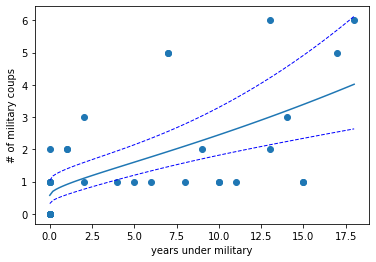

,mean,mean_se,mean_ci_lower,mean_ci_upper
0,0.576742,0.172889,0.320492,1.037875
1,0.700297,0.184300,0.418089,1.172995
2,0.758928,0.188643,0.466253,1.235321
3,0.807225,0.191821,0.506668,1.286073
4,0.850321,0.194404,0.543222,1.331033
...,...,...,...,...
96,3.863293,0.806631,2.565855,5.816786
97,3.901651,0.820824,2.583294,5.892819
98,3.940190,0.835185,2.600709,5.969565
99,3.978911,0.849714,2.618101,6.047029


In [28]:
# 1. predicting the sm.GLM(y, X) way:

# The scatter plot
plt.scatter(x="oligarchy", y="miltcoup", data=africa)
plt.xlabel("years under military")
plt.ylabel("# of military coups")


newOli_ = np.linspace(0, 18, num=101)  # as numpy.ndarray
Int_ = np.linspace(1.0, 1.0, num=101) # as numpy.ndarray

d = {'Intercept': list(Int_) , 'oligarchy': list(np.sqrt(newOli_))} # Convert to a dataframe
newOli = pd.DataFrame(data=d)                                      # oligarchy as sqrt(oligarchy)

preds = fnb.get_prediction(newOli).summary_frame(alpha=0.05) # response-type predictions

plt.plot(newOli_, preds['mean']) 
plt.plot(newOli_, preds['mean_ci_lower'], linestyle='dashed', color = "blue", linewidth=1.0)
plt.plot(newOli_, preds['mean_ci_upper'], linestyle='dashed', color = "blue", linewidth=1.0)


plt.show()

In [29]:
# predicting the sm.GLM.from_formula() way:
## NB
formula = "miltcoup ~ np.sqrt(oligarchy)"

fnb2 = sm.GLM.from_formula(formula, data=africa, family=sm.families.NegativeBinomial(alpha=0.07)).fit()
fnb2.summary() 

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:               miltcoup   No. Observations:                   36
Model:                            GLM   Df Residuals:                       34
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -51.858
Date:                Tue, 24 Oct 2023   Deviance:                       35.283
Time:                        12:22:39   Pearson chi2:                     34.2
No. Iterations:                     5   Pseudo R-squ. (CS):             0.4880
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.5504      0.300     -1.836      0.066      -1.138       0.037
np.sqrt(oligarchy)     0.4575      0.100      4.569      0.000       0.261       0.654
======================================================================================
"""

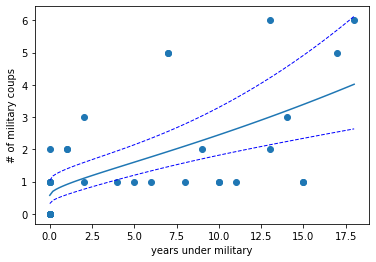

,mean,mean_se,mean_ci_lower,mean_ci_upper
0,0.576742,0.172889,0.320492,1.037875
1,0.700297,0.184300,0.418089,1.172995
2,0.758928,0.188643,0.466253,1.235321
3,0.807225,0.191821,0.506668,1.286073
4,0.850321,0.194404,0.543222,1.331033
...,...,...,...,...
96,3.863293,0.806631,2.565855,5.816786
97,3.901651,0.820824,2.583294,5.892819
98,3.940190,0.835185,2.600709,5.969565
99,3.978911,0.849714,2.618101,6.047029


In [30]:
# The scatter plot
plt.scatter(x="oligarchy", y="miltcoup", data=africa)
plt.xlabel("years under military")
plt.ylabel("# of military coups")


newOli_ = np.linspace(0, 18, num=101)  # as numpy.ndarray


d = {'oligarchy': list(newOli_)} # Convert to a dataframe
newOli = pd.DataFrame(data=d)             

preds = fnb2.get_prediction(newOli).summary_frame(alpha=0.05) # response-type predictions

plt.plot(newOli_, preds['mean']) 
plt.plot(newOli_, preds['mean_ci_lower'], linestyle='dashed', color = "blue", linewidth=1.0)
plt.plot(newOli_, preds['mean_ci_upper'], linestyle='dashed', color = "blue", linewidth=1.0)


plt.show()


This plot reveals one reason behind the belief of political scientists that military dictatorships do *not* stabilise nations, at least not in the long run.